# Explaining a credit risk model with SHAP and LIME

A bank refuses a loan and the client asks why. This notebook builds a credit risk model from the records of 150,000 borrowers and then explains its answers, for all clients together and for one client at a time.

1. **The model** (sections 1–3): the data, the cleaning, gradient boosting, how good it is.
2. **The explanations** (sections 4–6): SHAP, LIME, and the two side by side on the same clients.
3. **What they are worth** (sections 7–8): a fairness check on age, and four limits.

Units. A *risk* is the model's probability of default. A *contribution* is measured in percentage points of risk: "+14.3" means "this feature moves this client's risk up by 14.3 points".

In [1]:
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import shapiq
from lime.lime_tabular import LimeTabularExplainer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split

SEED = 42
DATA = Path("../data/cs-training.csv")
FIGURES = Path("../figures")

## 1. The question and the data

Source: Kaggle, [Give Me Some Credit](https://www.kaggle.com/c/GiveMeSomeCredit). One row per borrower. The file is not in the repository; `data/README.md` explains how to download it.

In [2]:
if not DATA.exists():
    raise FileNotFoundError(f"{DATA} not found. See data/README.md for the download steps.")
FIGURES.mkdir(exist_ok=True)

df = pd.read_csv(DATA, index_col=0)
print(df.shape)
df.head(3)

(150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0


| column | meaning |
|---|---|
| `SeriousDlqin2yrs` | **the target:** 1 = went 90 or more days past due within 2 years |
| `RevolvingUtilizationOfUnsecuredLines` | share of the credit card limit in use (0.5 = half) |
| `age` | years |
| `NumberOfTime30-59DaysPastDueNotWorse` | times 30–59 days late |
| `NumberOfTime60-89DaysPastDueNotWorse` | times 60–89 days late |
| `NumberOfTimes90DaysLate` | times 90 or more days late |
| `DebtRatio` | monthly debt payments ÷ monthly income |
| `MonthlyIncome` | income per month |
| `NumberOfOpenCreditLinesAndLoans` | open loans and credit cards |
| `NumberRealEstateLoansOrLines` | mortgages and other real-estate loans |
| `NumberOfDependents` | family members the borrower supports |

The model sees these ten numbers, plus one flag added during the cleaning, and nothing else.

In [3]:
base_rate = df["SeriousDlqin2yrs"].mean()
print(f"defaults: {df['SeriousDlqin2yrs'].sum():,} of {len(df):,} ({base_rate:.2%})")

defaults: 10,026 of 150,000 (6.68%)


About 1 borrower in 15 goes 90 days late. From here on that is called a **default**.

A model that answers "nobody defaults" is right 93% of the time and catches no one. Accuracy is the wrong yardstick for this problem.

## 2. Cleaning

Four problems in the raw file:

1. long, unreadable column names;
2. impossible values: one client of age 0, and late-payment counts of 96 and 98;
3. monthly income missing for one client in five;
4. extreme outliers: card usage reaches 50,708 where it should be around 0 to 1.

In [4]:
rename_map = {
    "SeriousDlqin2yrs": "default_2y",
    "RevolvingUtilizationOfUnsecuredLines": "card_usage",
    "age": "age",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59_days",
    "NumberOfTime60-89DaysPastDueNotWorse": "late_60_89_days",
    "NumberOfTimes90DaysLate": "late_90_plus_days",
    "DebtRatio": "debt_ratio",
    "MonthlyIncome": "monthly_income",
    "NumberOfOpenCreditLinesAndLoans": "open_credit_lines",
    "NumberRealEstateLoansOrLines": "real_estate_loans",
    "NumberOfDependents": "dependents",
}
clean = df.rename(columns=rename_map)

**Impossible values.** 96 and 98 are codes, not counts, and the data dictionary does not say what they mean. Those rows are removed and kept aside: they come back in section 8.

In [5]:
late_cols = ["late_30_59_days", "late_60_89_days", "late_90_plus_days"]
codes = clean[(clean[late_cols] >= 90).any(axis=1)]

print("age 0     :", (clean["age"] == 0).sum())
print("code 96/98:", len(codes))

clean = clean[(clean["age"] > 0) & (clean[late_cols] < 90).all(axis=1)]
print("rows left :", f"{len(clean):,}")

age 0     : 1
code 96/98: 269
rows left : 149,730


**Missing income.** A new column, `income_missing`, records the fact. Income is filled with the median. `debt_ratio` is debt divided by income, so without an income it is not a ratio: it is filled with the median too. Missing dependents become 0.

In [6]:
clean["income_missing"] = clean["monthly_income"].isna().astype(int)
clean.loc[clean["income_missing"] == 1, "debt_ratio"] = np.nan

clean["monthly_income"] = clean["monthly_income"].fillna(clean["monthly_income"].median())
clean["debt_ratio"] = clean["debt_ratio"].fillna(clean["debt_ratio"].median())
clean["dependents"] = clean["dependents"].fillna(0)

print("income missing:", f"{clean['income_missing'].sum():,}")

income missing: 29,610


**Outliers.** The top 1% of three columns is capped at the 99th percentile.

In [7]:
for col in ["card_usage", "debt_ratio", "monthly_income"]:
    cap = clean[col].quantile(0.99)
    clean[col] = clean[col].clip(upper=cap)
    print(f"{col:15s} capped at {cap:,.2f}")

card_usage      capped at 1.09
debt_ratio      capped at 268.13
monthly_income  capped at 23,012.07


In [8]:
assert clean.isna().sum().sum() == 0

print("shape:", clean.shape)
print(f"default rate after cleaning: {clean['default_2y'].mean():.2%}")

shape: (149730, 12)
default rate after cleaning: 6.60%


After cleaning: 149,730 borrowers, 11 features, 6.60% defaults.

The medians and the caps above are computed on all rows, before the split into training and test data. Computed on the training rows alone they barely change: the medians are the same to two decimals, and the card-usage cap is 1.10 where it is 1.09 here.

## 3. The model

**Split.** 80% of the clients to train, 20% to test, with the same default rate on both sides (`stratify`).

The features are stored as 32-bit numbers because SHAP's tree code stores the split thresholds of the trees in 32 bits. If the model is trained on 64-bit values, some clients land on the other side of a threshold inside SHAP, and the contributions stop adding up to the prediction.

In [9]:
y = clean["default_2y"]
X = clean.drop(columns=["default_2y"]).astype("float32")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print(f"train: {X_train.shape}  default rate {y_train.mean():.2%}")
print(f"test : {X_test.shape}  default rate {y_test.mean():.2%}")
print(f"'nobody defaults' on the test set: accuracy {1 - y_test.mean():.2%}, caught 0 of {y_test.sum():,}")

train: (119784, 11)  default rate 6.60%
test : (29946, 11)  default rate 6.60%
'nobody defaults' on the test set: accuracy 93.40%, caught 0 of 1,976


**The model.** Gradient boosting builds small decision trees one after another. Each tree corrects the errors left by the trees before it, and the final risk comes from the sum of all their answers. Training stops by itself when a held-out part of the training data stops improving.

In [10]:
model = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.1, max_depth=4, random_state=SEED
)
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)[:, 1]

print("trees:", model.n_iter_)
print(f"AUC  : {roc_auc_score(y_test, y_proba):.3f}")

trees: 86
AUC  : 0.859


AUC 0.859: take one defaulter and one non-defaulter at random, and the model gives the higher risk to the defaulter about 86 times out of 100.

The model gives a risk. A decision needs a cut-off: refuse everyone above it.

In [11]:
rows = []
for cutoff in [0.5, 0.3, 0.2, 0.1, 0.066]:
    tn, fp, fn, tp = confusion_matrix(y_test, (y_proba >= cutoff).astype(int)).ravel()
    rows.append({
        "cut-off": cutoff,
        "defaulters caught": tp,
        "caught %": 100 * tp / (tp + fn),
        "precision %": 100 * tp / (tp + fp),
        "good clients flagged": fp,
        "accuracy %": 100 * (tp + tn) / len(y_test),
    })
pd.DataFrame(rows).set_index("cut-off").round(1)

,defaulters caught,caught %,precision %,good clients flagged,accuracy %
cut-off,,,,,
0.500,333,16.9,62.0,204,93.8
0.300,735,37.2,46.3,853,93.0
0.200,938,47.5,39.2,1457,91.7
0.100,1280,64.8,26.9,3480,86.1
0.066,1528,77.3,20.7,5843,79.0


At the usual cut-off of 0.5 the model catches 333 of 1,976 defaulters (17%), and its accuracy (93.8%) is barely above the 93.4% of "nobody defaults". At 0.2 it catches 938 (47%) and wrongly flags 1,457 good clients.

No cut-off is correct in itself. The choice depends on what a missed default and a refused good client cost the bank. Section 7 uses 0.2.

## 4. SHAP

### 4.1 The idea, by hand

Several players produce a result together. A Shapley value says how much of that result is due to each one.

The recipe: let the players join one at a time, in every possible order. Each time a player joins, note how much the result grows. The player's Shapley value is the average of those increases.

Three workers, A, B and C. The table says what each possible team earns.

In [12]:
value = {
    (): 0,
    ("A",): 30,
    ("B",): 10,
    ("C",): 6,
    ("A", "B"): 34,
    ("A", "C"): 34,
    ("B", "C"): 14,
    ("A", "B", "C"): 42,
}

def team_value(members):
    return value[tuple(sorted(members))]

players = ["A", "B", "C"]
orders = list(permutations(players))
shapley = {p: 0.0 for p in players}

for order in orders:
    present = []
    for player in order:
        before = team_value(present)
        present.append(player)
        shapley[player] += team_value(present) - before

shapley = {p: total / len(orders) for p, total in shapley.items()}

print(shapley)
assert abs(sum(shapley.values()) - team_value(players)) < 1e-9

{'A': 28.0, 'B': 8.0, 'C': 6.0}


A = 28, B = 8, C = 6, and 28 + 8 + 6 = 42. The shares always add up to the whole.

SHAP applies the same recipe to a model. The players are the features. The result is one client's predicted risk. "A feature has not joined yet" means: its value is replaced with the values of other clients, the *background*, and the predictions are averaged. Three facts follow.

- A client's contributions add up exactly to the gap between that client's risk and the average risk.
- A feature that never changes the prediction gets exactly 0.
- The numbers depend on the background. Another reference group gives other contributions.

### 4.2 SHAP on the model

- **Background:** 2,000 training clients. They go through a masker because `TreeExplainer` otherwise keeps only 100 of them.
- **`model_output="probability"`:** contributions are in probability, not in log-odds, so they read as points of risk. `TreeExplainer` gets there by computing each contribution in log-odds against every background client and rescaling it so that the total matches the probability. The total is exact. The split between the features is close to the Shapley values of the probability, not identical; section 4.6 measures the difference for one client.
- The first 5,000 test clients are explained.

In [13]:
background = shap.utils.sample(X_train, 2000, random_state=SEED)
masker = shap.maskers.Independent(background, max_samples=2000)

explainer = shap.TreeExplainer(
    model,
    masker,
    model_output="probability",
    feature_perturbation="interventional",
)

X_explain = X_test.iloc[:5000]
shap_values = explainer(X_explain)

print("base value:", round(float(shap_values.base_values[0]), 4))
print("shape     :", shap_values.values.shape)

base value: 0.0657
shape     : (5000, 11)


The base value, 6.57%, is the average prediction over the background: the risk of a client we know nothing about. It is close to the 6.60% default rate.

For every one of the 5,000 clients, base value plus contributions must equal the model's prediction. The next cell stops with an error if it does not.

In [14]:
rebuilt = shap_values.base_values + shap_values.values.sum(axis=1)
gap = np.abs(rebuilt - y_proba[:5000]).max()

assert gap < 1e-6
print(f"largest gap between SHAP's total and the model's prediction: {gap:.1e}")

largest gap between SHAP's total and the model's prediction: 1.5e-08


### 4.3 All clients: which features matter

The importance of a feature is the average size of its contribution, ignoring the sign.

In [15]:
importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0) * 100, index=X.columns
).sort_values(ascending=False)

importance.round(2).to_frame("mean |SHAP| (points)")

,mean |SHAP| (points)
card_usage,2.95
late_90_plus_days,1.99
late_30_59_days,1.91
late_60_89_days,1.16
age,0.85
open_credit_lines,0.68
debt_ratio,0.59
real_estate_loans,0.38
monthly_income,0.38
dependents,0.12


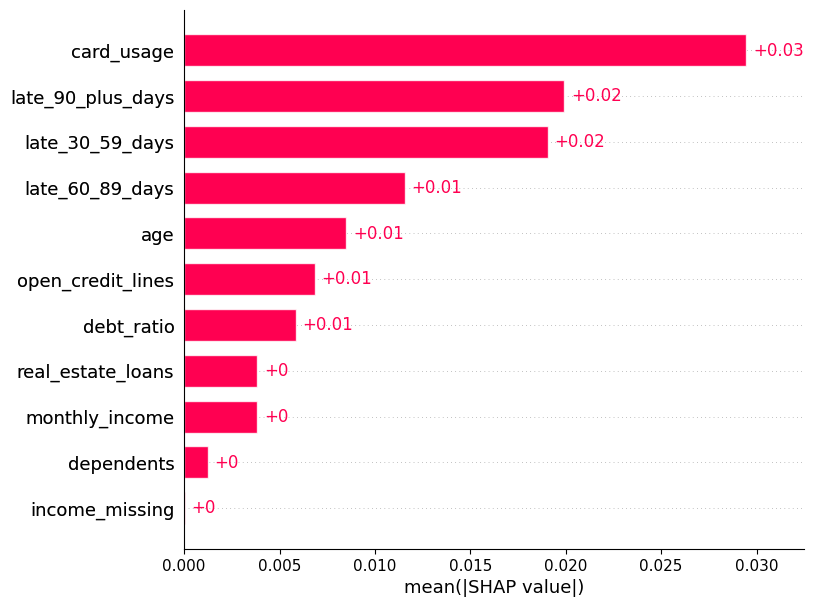

In [16]:
shap.plots.bar(shap_values, max_display=11, show=False)
plt.savefig(FIGURES / "shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

`card_usage` moves a client's risk by 2.95 points on average, more than any other feature. The three late-payment counts follow (1.99, 1.91 and 1.16). `income_missing` is at 0.00: section 8 comes back to it. The chart shows the same values as probabilities (0.03 = 3 points).

The bar chart has no direction. The next chart has one dot per client and per feature.

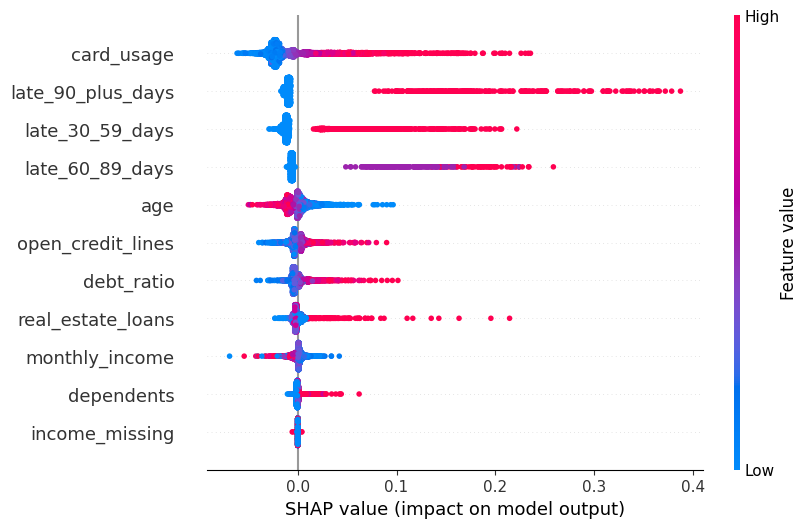

In [17]:
shap.plots.beeswarm(shap_values, max_display=11, show=False)
plt.savefig(FIGURES / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

Red is a high value of the feature, blue a low one. A dot on the right pushes the risk up. The horizontal axis is a probability: 0.1 is 10 points.

High card usage and any late payment push the risk up. A delay of 90 days or more adds over 30 points for some clients. For `age` the colours are reversed: young clients are pushed up, older clients down.

### 4.4 The shape of an effect

The next chart shows how the contribution changes along one feature. Each dot is a client.

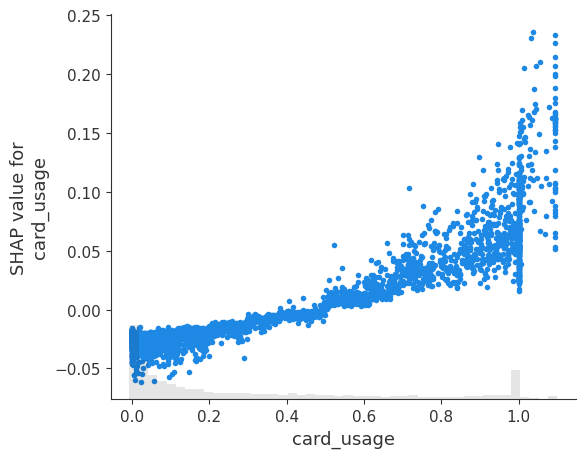

In [18]:
shap.plots.scatter(shap_values[:, "card_usage"])

The contribution of `card_usage` rises with the usage. The table gives the average for each band.

In [19]:
def mean_shap_by(feature, groups):
    points = pd.Series(shap_values[:, feature].values * 100, index=X_explain.index)
    out = points.groupby(groups, observed=True).agg(["mean", "size"])
    out.columns = ["mean SHAP (points)", "clients"]
    return out.round(1)

usage_band = pd.cut(
    X_explain["card_usage"],
    bins=[-0.01, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 1.1],
    labels=["0–10%", "10–30%", "30–50%", "50–70%", "70–90%", "90–100%", "over 100%"],
)
mean_shap_by("card_usage", usage_band)

,mean SHAP (points),clients
card_usage,,
0–10%,-2.5,2131
10–30%,-2.0,945
30–50%,-0.6,558
50–70%,1.4,382
70–90%,4.3,315
90–100%,6.6,554
over 100%,13.4,115


A steady ramp: from −2.5 points for clients who use less than 10% of their limit to +6.6 at 90–100%, then a jump to +13.4 for the 115 clients over their limit.

A second method asks the same question in a different way. Partial dependence sets every client to the same card usage, averages the predictions, and repeats for each value.

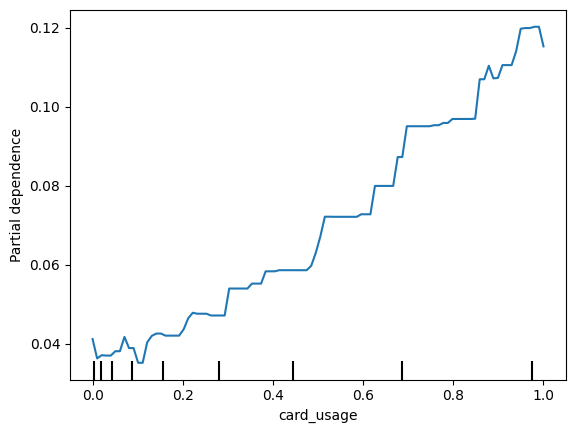

In [20]:
PartialDependenceDisplay.from_estimator(
    model,
    X_explain.astype("float64"),  # the method writes new values into the table and needs 64-bit columns
    ["card_usage"],
    method="brute",
    response_method="predict_proba",
)
plt.show()

The average prediction rises from 4.1% at zero usage to 11.5% with a full card. The shape is the same, and this method does not use Shapley values.

Late payments behave differently.

In [21]:
late_30 = mean_shap_by("late_30_59_days", X_explain["late_30_59_days"].clip(upper=3).astype(int))
late_90 = mean_shap_by("late_90_plus_days", X_explain["late_90_plus_days"].clip(upper=3).astype(int))

pd.concat({"30–59 days late": late_30, "90+ days late": late_90}, axis=1).rename_axis("times (3 = three or more)")

30–59 days late              90+ days late  \
                          mean SHAP (points) clients mean SHAP (points)   
times (3 = three or more)                                                 
0                                       -1.2    4235               -1.0   
1                                        3.6     538               14.6   
2                                        8.8     134               24.1   
3                                       14.1      93               31.7   

                                   
                          clients  
times (3 = three or more)          
0                            4728  
1                             173  
2                              52  
3                              47

Short delays add up steadily: +3.6 points for one delay of 30–59 days, +8.8 for two, +14.1 for three or more. With delays of 90 days or more the first one costs the most: +14.6 for one, +24.1 for two. A single delay of 90 days weighs as much as three or more short ones.

### 4.5 One client at a time

Three test clients, chosen because they have three different stories.

In [22]:
clients = {"debt": 0, "late payer": 1961, "safe": 4625}

profile = X_test.iloc[list(clients.values())].T
profile.columns = list(clients)
profile.loc["risk (%)"] = [y_proba[i] * 100 for i in clients.values()]
profile.loc["defaulted"] = [y_test.iloc[i] for i in clients.values()]
profile.round(2)

,debt,late payer,safe
card_usage,0.41,0.96,0.00
age,51.00,49.00,69.00
late_30_59_days,0.00,6.00,0.00
debt_ratio,1.26,1.73,0.00
monthly_income,6620.00,6416.00,3800.00
open_credit_lines,23.00,15.00,5.00
late_90_plus_days,0.00,2.00,0.00
real_estate_loans,9.00,8.00,0.00
late_60_89_days,0.00,3.00,0.00
dependents,3.00,0.00,0.00


A waterfall starts from the base value (6.57%) and adds one bar per feature until it reaches the client's risk.

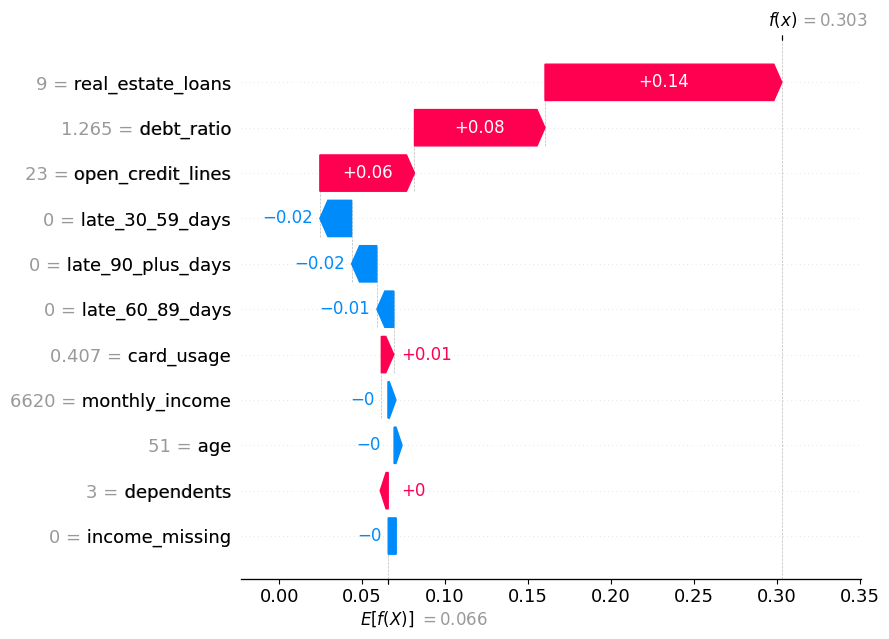

In [23]:
shap.plots.waterfall(shap_values[clients["debt"]], max_display=11, show=False)
plt.savefig(FIGURES / "waterfall_debt_client.png", dpi=150, bbox_inches="tight")
plt.show()

**The debt client: 30.3%.** Never late, so the three late-payment features pull the risk down (−1.9, −1.5, −1.0). Debt pushes it up: 9 real-estate loans (+14.3), a debt ratio of 1.26 (+7.9), 23 open credit lines (+5.7). This client did default.

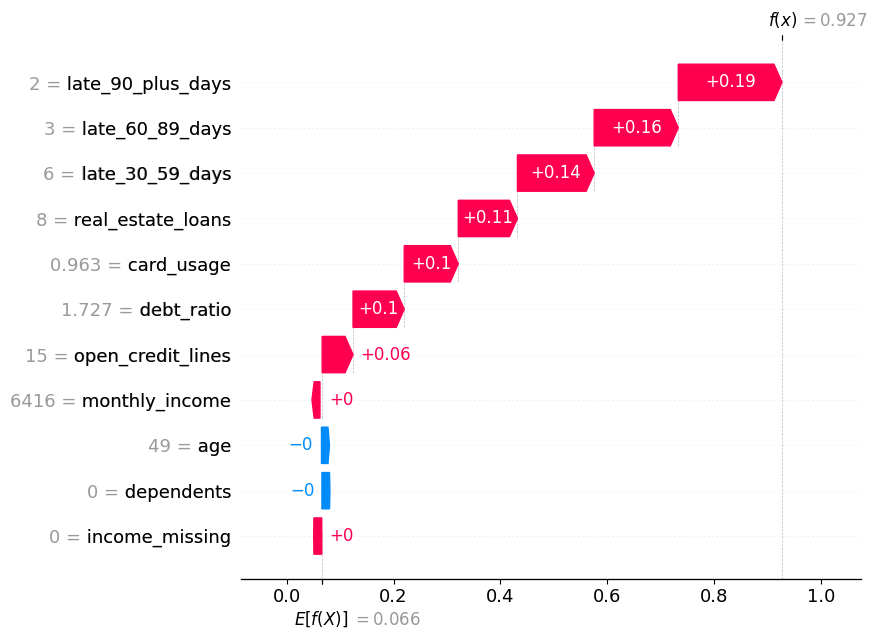

In [24]:
shap.plots.waterfall(shap_values[clients["late payer"]], max_display=11)

**The late payer: 92.7%.** Two delays of 90 days or more, three of 60–89, six of 30–59, and a card at 96% of its limit. The three late-payment features give +19.4, +15.7 and +14.4. This client defaulted too.

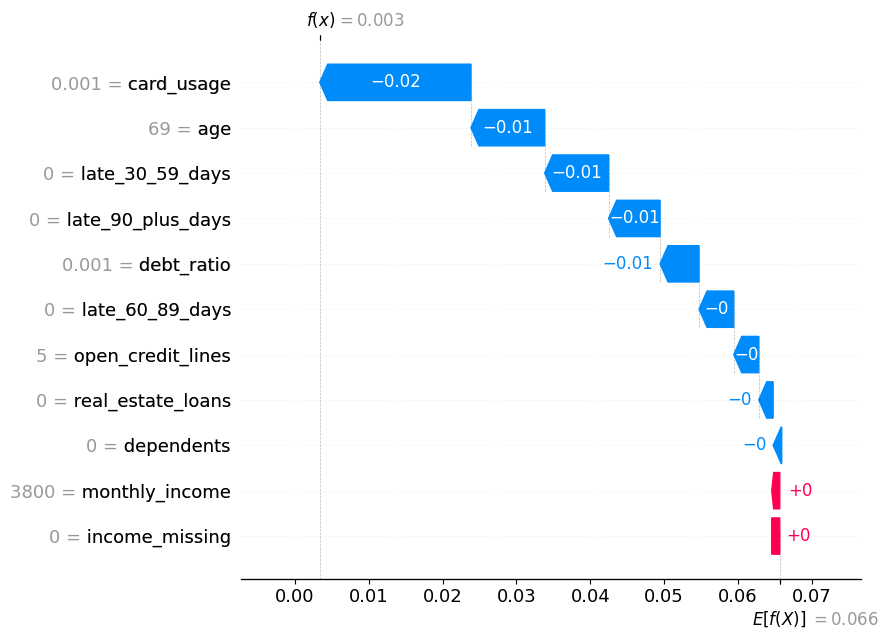

In [25]:
shap.plots.waterfall(shap_values[clients["safe"]], max_display=11)

**The safe client: 0.3%.** An empty card (−2.0), 69 years old (−1.0), never late. Every bar is small and almost all of them point down. No default.

The same model has a different reason for each of the three clients. The global ranking of section 4.3 cannot show that.

### 4.6 Interactions

SHAP gives one number per feature. When two features matter only *together*, SHAP splits their joint effect between the two bars. SHAP-IQ (`shapiq`) reports it separately: one number for each feature on its own, and one for each pair.

Same model, same 2,000 background clients. `budget=2**11` evaluates all 2,048 combinations of the 11 features, so the result is exact. With `max_order=2` the effects of three or more features together are folded into these numbers.

In [26]:
def predict_both(rows):
    rows = pd.DataFrame(rows, columns=X.columns).astype("float32")
    return model.predict_proba(rows)

def predict_risk(rows):
    return predict_both(rows)[:, 1]

iq_explainer = shapiq.TabularExplainer(
    model=predict_risk,
    data=background.values,
    index="k-SII",
    max_order=2,
    sample_size=2000,  # the default uses 100 background clients
    random_state=SEED,
)

iq_debt = iq_explainer.explain(X_test.iloc[clients["debt"]].values, budget=2**11)
iq_late = iq_explainer.explain(X_test.iloc[clients["late payer"]].values, budget=2**11)

def strongest(iq, k=6):
    names = list(X.columns)
    terms = {" × ".join(names[j] for j in key): v * 100 for key, v in iq.dict_values.items() if key}
    return pd.Series(terms).sort_values(key=abs, ascending=False).head(k).round(1).to_frame("points")

In [27]:
strongest(iq_debt)

,points
debt_ratio × real_estate_loans,11.1
open_credit_lines × real_estate_loans,6.5
debt_ratio × open_credit_lines,3.5
real_estate_loans,3.4
card_usage × real_estate_loans,2.0
open_credit_lines,1.5


**The debt client: synergy.** On their own the 9 real-estate loans are worth +3.4 points. Their pair with the debt ratio is worth +11.1, and their pair with the open credit lines +6.5. For this model, many real-estate loans are dangerous when they come with high debt.

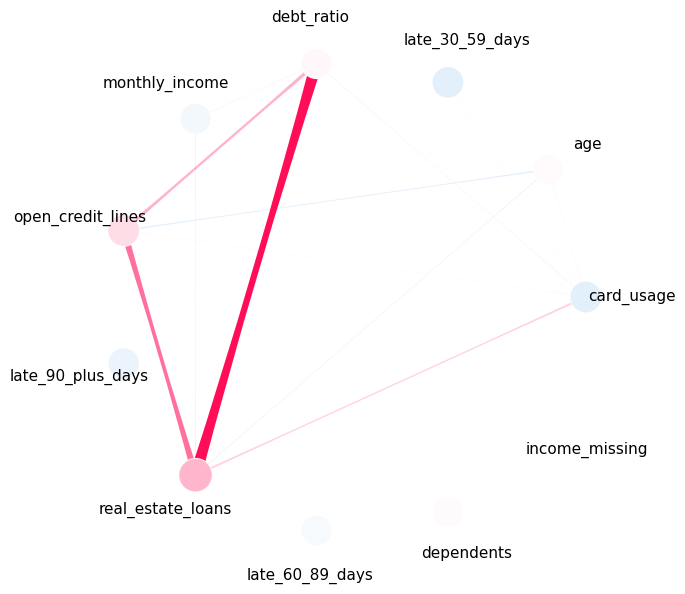

In [28]:
fig, _ = shapiq.network_plot(interaction_values=iq_debt, feature_names=list(X.columns))
fig.savefig(FIGURES / "interactions_debt_client.png", dpi=150, bbox_inches="tight")
plt.show()

In the plot a circle is one feature and a line is a pair. Red pushes the risk up, blue down. The thicker and darker a line, the stronger the pair.

Sharing each pair equally between its two features gives one number per feature again.

In [29]:
def shared_out(iq):
    names = list(X.columns)
    total = pd.Series(0.0, index=names)
    for key, v in iq.dict_values.items():
        for j in key:
            total[names[j]] += v * 100 / len(key)
    return total

pd.DataFrame({
    "SHAP-IQ, pairs shared out": shared_out(iq_debt),
    "SHAP (TreeExplainer)": pd.Series(shap_values[clients["debt"]].values * 100, index=X.columns),
}).sort_values("SHAP (TreeExplainer)", ascending=False).head(3).round(1)

,"SHAP-IQ, pairs shared out",SHAP (TreeExplainer)
real_estate_loans,12.9,14.3
debt_ratio,8.1,7.9
open_credit_lines,6.1,5.7


The first column holds the Shapley values of the predicted probability: 12.9, 8.1 and 6.1. `TreeExplainer` gave 14.3, 7.9 and 5.7. The order is the same and the sizes are close; the difference is the rescaling described in section 4.2. Of the 12.9 points that go to the real-estate loans, 3.4 are their own and the rest is their half of the pairs.

In [30]:
strongest(iq_late, k=8)

,points
late_90_plus_days,29.2
late_60_89_days,23.8
late_30_59_days,16.5
real_estate_loans,10.9
late_30_59_days × late_60_89_days,-9.5
card_usage,8.9
debt_ratio × real_estate_loans,8.7
late_90_plus_days × late_60_89_days,-6.0


**The late payer: redundancy.** The three late-payment features are large on their own (+29.2, +23.8, +16.5) and two of their pairs are negative (−9.5 and −6.0). The three features tell the same story, and the negative pairs take the double counting out.

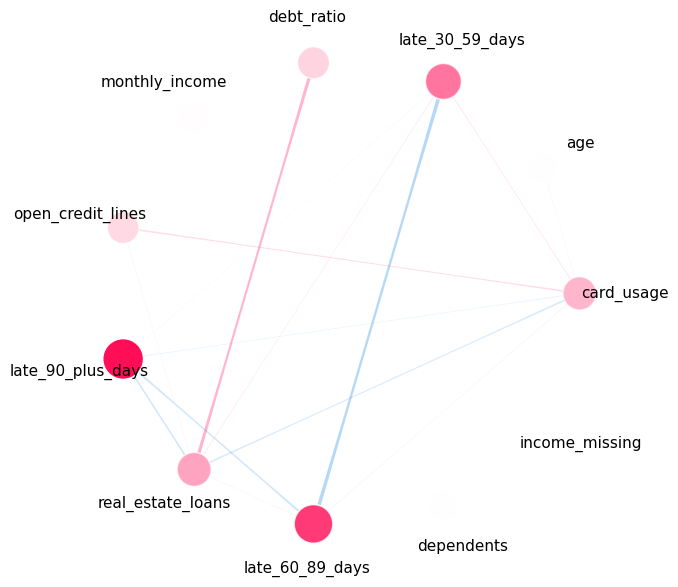

In [31]:
fig, _ = shapiq.network_plot(interaction_values=iq_late, feature_names=list(X.columns))
plt.show()

The blue lines between the late-payment features are the negative pairs.

## 5. LIME

LIME explains one client with a different idea: close to that client, the model can be approximated by a straight line.

1. Create fake clients near the real one.
2. Ask the model for their risk.
3. Give more weight to the fake clients that are closer.
4. Fit a weighted straight line. Its slopes are the explanation.

### 5.1 By hand

This version makes a fake client by keeping some of the real client's values and swapping the others with the values of a random real client. A fake client is close when few values were swapped. This keep-or-swap scheme is the game SHAP plays too, with other weights and a fitted line in place of the Shapley average, so its answers should land close to SHAP's.

In [32]:
def lime_hand(i, seed=SEED, n=1000):
    client = X_test.iloc[i]
    rng = np.random.default_rng(seed)

    # 1. fake clients: each value is kept (1) or swapped with a random real client's value (0)
    keep = rng.integers(0, 2, size=(n, X.shape[1]))
    donors = X_train.sample(n, random_state=seed)
    neighbours = pd.DataFrame(np.where(keep == 1, client.values, donors.values), columns=X.columns)

    # 2. the model's risk for each fake client
    risk = model.predict_proba(neighbours)[:, 1]

    # 3. weights: few swaps -> close to 1, many swaps -> close to 0
    changed = X.shape[1] - keep.sum(axis=1)
    weight = np.exp(-(changed**2) / 4**2)

    # 4. weighted straight line on the keep/swap table: one slope per feature
    line = LinearRegression().fit(keep, risk, sample_weight=weight)
    slopes = pd.Series(line.coef_ * 100, index=X.columns)
    guess = (line.intercept_ + line.coef_.sum()) * 100
    return slopes, guess

In [33]:
slopes, guess = lime_hand(clients["debt"])

print(slopes.sort_values(ascending=False).round(1).to_string())
print()
print("line, every value kept    :", round(guess, 1))
print("line, every value swapped :", round(guess - slopes.sum(), 1))
print("model                     :", round(y_proba[clients["debt"]] * 100, 1))

real_estate_loans    15.6
debt_ratio            9.9
open_credit_lines     6.8
dependents            3.2
monthly_income        1.7
income_missing        1.0
card_usage            0.7
late_30_59_days      -0.5
late_90_plus_days    -0.9
late_60_89_days      -1.0
age                  -1.6

line, every value kept    : 29.3
line, every value swapped : -5.4
model                     : 30.3


A slope reads: "keeping this client's own value, instead of a random client's, changes the risk by this many points". The top three are the same as SHAP's, in the same order: real-estate loans +15.6, debt ratio +9.9, open credit lines +6.8 (SHAP: +14.3, +7.9, +5.7).

The line has two ends. With every value kept it should give the client's risk: it says 29.3 and the model says 30.3. With every value swapped it says −5.4, a risk that cannot exist. The line is an approximation, and nothing forces it to add up. With 20,000 fake clients the first end settles at 25.3 (section 6), so part of the 29.3 is luck.

### 5.2 The `lime` library

The library follows the same four steps with other choices. It draws the fake clients from the distribution of each feature, cuts every feature into at most four bins (quartiles), and fits a Ridge regression on "is the fake client in the same bin as the real one?".

In [34]:
def lime_library(i, seed=SEED, n=5000):
    lime_explainer = LimeTabularExplainer(
        X_train.values,
        feature_names=list(X.columns),
        class_names=["no default", "default"],
        mode="classification",
        random_state=seed,
    )
    return lime_explainer.explain_instance(
        X_test.iloc[i].values, predict_both, num_features=X.shape[1], num_samples=n
    )

In [35]:
exp = lime_library(clients["debt"])

print("line's guess:", round(exp.local_pred[0] * 100, 1))
print("model       :", round(y_proba[clients["debt"]] * 100, 1))
print("R² of the line:", round(exp.score, 2))

rules = pd.DataFrame(exp.as_list(), columns=["rule", "slope (points)"])
rules["slope (points)"] *= 100
rules.round(1)

line's guess: 10.2
model       : 30.3
R² of the line: 0.52


,rule,slope (points)
0,late_90_plus_days <= 0.00,-22.3
1,late_60_89_days <= 0.00,-13.4
2,late_30_59_days <= 0.00,-7.9
3,real_estate_loans > 2.00,4.1
4,open_credit_lines > 11.00,2.4
5,debt_ratio > 0.43,1.6
6,0.15 < card_usage <= 0.56,-0.8
7,dependents > 1.00,0.5
8,41.00 < age <= 52.00,0.2
9,income_missing <= 0.00,0.2


The library gives a different explanation. The three largest terms are now the "never late" rules (−22.3, −13.4, −7.9), and the real-estate loans are worth only +4.1. The line's guess is 10.2% against the model's 30.3%, and its R² is 0.52.

There are two causes.

- **Bins hide extreme values.** The rule is `real_estate_loans > 2`: 3 loans and 9 loans are the same thing to the line.
- **The comparison is different.** A slope compares "in this bin" with "in any other bin", not this client with a typical client.

### 5.3 Stability

The fake clients are random, so the answer depends on the seed.

In [36]:
top3 = ["real_estate_loans", "debt_ratio", "open_credit_lines"]
seeds = [SEED, 7, 1, 2, 3]

def by_seed(n):
    runs = {seed: lime_hand(clients["debt"], seed=seed, n=n)[0] for seed in seeds}
    return pd.DataFrame(runs).loc[top3]

pd.concat({"1,000 fake clients": by_seed(1000), "20,000 fake clients": by_seed(20000)}).rename_axis(columns="seed").round(1)

seed                                     42    7     1     2     3 
1,000 fake clients  real_estate_loans  15.6  13.7  12.5  13.6  14.2
                    debt_ratio          9.9   8.6  10.9  10.1  10.1
                    open_credit_lines   6.8   6.1   6.7   6.0   6.9
20,000 fake clients real_estate_loans  14.7  14.7  14.7  14.5  14.8
                    debt_ratio          9.2   9.4   9.4   9.4   9.9
                    open_credit_lines   6.4   6.6   6.5   6.5   6.8

With 1,000 fake clients the slope of the real-estate loans moves between 12.5 and 15.6 from one seed to the next. With 20,000 it stays between 14.5 and 14.8. The order of the top three does not change. More fake clients give steadier answers.

In [37]:
loans = list(X.columns).index("real_estate_loans")

runs = {}
for seed in seeds:
    exp = lime_library(clients["debt"], seed=seed)
    runs[seed] = {
        "real_estate_loans slope": dict(exp.as_map()[1])[loans] * 100,
        "line's guess": exp.local_pred[0] * 100,
    }
pd.DataFrame(runs).rename_axis(columns="seed").round(1)

seed,42,7,1,2,3
real_estate_loans slope,4.1,3.1,3.7,3.2,3.1
line's guess,10.2,8.5,9.3,9.3,9.2


The library moves too: its guess for the same client goes from 8.5 to 10.2. TreeSHAP has no random step once the background is fixed. The same inputs give the same numbers.

## 6. SHAP vs LIME

Same model, same three clients, three explanations. LIME uses a fixed seed here, and the by-hand version uses 20,000 fake clients.

In [38]:
def compare(i):
    hand, _ = lime_hand(i, n=20000)
    library = pd.Series({X.columns[j]: w * 100 for j, w in lime_library(i).as_map()[1]})
    table = pd.DataFrame({
        "value": X_test.iloc[i],
        "SHAP": pd.Series(shap_values[i].values * 100, index=X.columns),
        "LIME by hand": hand,
        "LIME library": library,
    })
    return table.sort_values("SHAP", ascending=False).round(2)

compare(clients["debt"])

,value,SHAP,LIME by hand,LIME library
real_estate_loans,9.00,14.28,14.73,4.08
debt_ratio,1.26,7.87,9.18,1.63
open_credit_lines,23.00,5.71,6.39,2.43
card_usage,0.41,0.75,0.88,-0.82
dependents,3.00,0.35,0.21,0.45
income_missing,0.00,-0.00,-0.05,0.18
age,51.00,-0.37,-1.05,0.25
monthly_income,6620.00,-0.40,-0.28,0.02
late_60_89_days,0.00,-1.02,-1.15,-13.40
late_90_plus_days,0.00,-1.52,-1.18,-22.29


**The debt client.** SHAP and LIME by hand tell one story: +14.3 and +14.7 for the real-estate loans, +7.9 and +9.2 for the debt ratio, +5.7 and +6.4 for the open credit lines. The library puts its weight on the "never late" rules.

In [39]:
compare(clients["late payer"])

,value,SHAP,LIME by hand,LIME library
late_90_plus_days,2.00,19.39,20.23,22.81
late_60_89_days,3.00,15.73,14.50,14.17
late_30_59_days,6.00,14.35,13.74,8.13
real_estate_loans,8.00,11.07,13.77,4.28
card_usage,0.96,10.11,10.43,7.99
debt_ratio,1.73,9.58,12.71,1.53
open_credit_lines,15.00,5.77,6.53,2.69
monthly_income,6416.00,0.41,0.65,0.08
income_missing,0.00,0.04,0.24,0.23
dependents,0.00,-0.08,0.15,-0.39


**The late payer.** SHAP and LIME by hand are close again. The library agrees on the first two features and flattens the others: the debt ratio is worth +9.6 for SHAP and +1.5 for the library.

In [40]:
compare(clients["safe"])

,value,SHAP,LIME by hand,LIME library
monthly_income,3800.0,0.03,0.01,0.74
income_missing,0.0,0.00,0.02,0.20
dependents,0.0,-0.12,-0.03,-0.48
real_estate_loans,0.0,-0.19,-0.17,-0.16
open_credit_lines,5.0,-0.34,-0.39,-1.48
late_60_89_days,0.0,-0.47,-0.50,-13.31
debt_ratio,0.0,-0.53,-0.62,-0.29
late_90_plus_days,0.0,-0.70,-0.65,-21.78
late_30_59_days,0.0,-0.87,-0.79,-7.80
age,69.0,-1.00,-0.92,-2.32


**The safe client.** For SHAP and LIME by hand every contribution is small. The library gives −21.8, −13.3 and −7.8 to the "never late" rules, more than 40 points of reduction for a client whose risk is 6 points below the average.

**Totals.** What each explanation adds up to, next to the model's answer.

In [41]:
def totals(i):
    return {
        "model": y_proba[i] * 100,
        "SHAP": (shap_values[i].base_values + shap_values[i].values.sum()) * 100,
        "LIME by hand": lime_hand(i, n=20000)[1],
        "LIME library": lime_library(i).local_pred[0] * 100,
    }

pd.DataFrame({name: totals(i) for name, i in clients.items()}).T.round(1)

,model,SHAP,LIME by hand,LIME library
debt,30.3,30.3,25.3,10.2
late payer,92.7,92.7,103.0,61.8
safe,0.3,0.3,-0.3,-2.2


SHAP matches the model every time. LIME by hand is 5 points low for the debt client, and for the late payer its line gives 103%, an impossible risk. The library is far off for all three clients: 10.2 against 30.3, 61.8 against 92.7, −2.2 against 0.3.

**Ranking.** Spearman correlation with SHAP's ranking of the features; 1 means the same order.

In [42]:
methods = ["SHAP", "LIME by hand", "LIME library"]

agreement = {name: compare(i)[methods].corr(method="spearman")["SHAP"] for name, i in clients.items()}
pd.DataFrame(agreement).T[methods[1:]].round(2)

,LIME by hand,LIME library
debt,0.99,0.86
late payer,0.98,0.92
safe,0.99,0.74


LIME by hand ranks the features almost exactly as SHAP does (0.98–0.99). That is expected, because it is built on SHAP's keep-or-swap idea. The library is the independent method, and it is lower (0.74–0.92).

| | SHAP | LIME |
|---|---|---|
| compares the client with | the average prediction over the background | fake clients near the real one |
| adds up to the model's answer | always | only roughly |
| same answer on every run | yes | no, it depends on the seed |
| extreme values (9 real-estate loans) | kept | hidden by the bins (library) |
| works on | tree models, in this fast form | any model that returns a prediction |

**Verdict**

- **SHAP for the explanation given to the client.** Its total always matches the model, it is repeatable, and it keeps extreme values.
- **LIME as a second opinion, with care.** The by-hand version tells SHAP's story, as expected from a method built on the same idea. The library is the independent check, and on these three clients its line fits poorly.
- **Check LIME's guess against the model before reading its slopes.** A line that says 10.2% where the model says 30.3% explains a different function.
- LIME's strength does not show on this model. It needs nothing but predictions, so it also works on text and images and on models without a fast exact SHAP.

## 7. Fairness: age

The explanations are faithful to the model. That says nothing about whether the model treats people fairly. Age is a personal attribute, and section 4.3 showed that the model uses it.

**Risk by age group**

In [43]:
test = X_test.copy()
test["risk"] = y_proba
test["defaulted"] = y_test
test["age_group"] = pd.cut(
    test["age"],
    bins=[0, 30, 40, 50, 60, 70, 120],
    labels=["up to 30", "31–40", "41–50", "51–60", "61–70", "over 70"],
)

by_age = test.groupby("age_group", observed=True).agg(
    clients=("risk", "size"),
    real_default=("defaulted", "mean"),
    predicted_risk=("risk", "mean"),
)
by_age[["real_default", "predicted_risk"]] *= 100
by_age.round(1)

,clients,real_default,predicted_risk
age_group,,,
up to 30,2123,11.4,10.8
31–40,4874,9.8,9.5
41–50,6967,8.4,7.9
51–60,6987,5.8,6.0
61–70,5471,3.3,3.6
over 70,3524,2.6,2.1


In the data young clients default more often (11.4% up to 30, 2.6% over 70), and the model's average risk follows closely (10.8% and 2.1%). On average the model is right about every age group, within about half a point.

**Refusals by age group.** Cut-off 0.2: a client at 20% risk or more is refused.

In [44]:
test["refused"] = test["risk"] >= 0.2
good = test[test["defaulted"] == 0]

pd.DataFrame({
    "refused %": test.groupby("age_group", observed=True)["refused"].mean() * 100,
    "good clients refused %": good.groupby("age_group", observed=True)["refused"].mean() * 100,
}).round(1)

,refused %,good clients refused %
age_group,,
up to 30,15.2,10.9
31–40,13.1,8.7
41–50,9.9,6.0
51–60,6.9,4.8
61–70,3.6,2.4
over 70,1.7,1.1


15.2% of the clients up to 30 are refused, and 1.7% of those over 70. Among clients who did **not** default, 10.9% of the youngest are refused against 1.1% of the oldest. A good young client is ten times more likely to be refused than a good older one.

The two checks disagree, and that is expected. When two groups default at different rates, a model cannot be calibrated in both and also have the same error rates in both, unless it predicts perfectly (Kleinberg, Mullainathan and Raghavan, 2017; Chouldechova, 2017). Which of the two a lender must satisfy is a legal and business question.

**Age itself or behaviour.** SHAP splits each group's distance from the average in two: the push from `age`, and the push from all the other features.

In [45]:
explained = test.iloc[:5000].copy()
age_push = shap_values[:, "age"].values * 100
explained["push from age"] = age_push
explained["push from the rest"] = shap_values.values.sum(axis=1) * 100 - age_push

explained.groupby("age_group", observed=True)[["push from age", "push from the rest"]].mean().round(1)

,push from age,push from the rest
age_group,,
up to 30,2.3,2.5
31–40,1.0,1.7
41–50,0.3,1.4
51–60,-0.3,-0.3
61–70,-1.1,-1.8
over 70,-1.2,-3.4


For the youngest group `age` alone adds 2.3 points and the other features together add 2.5. For the oldest group the two numbers are −1.2 and −3.4. So, among the 5,000 explained clients, 3.5 of the 9.4 points between the two groups come from age itself, and 5.9 from how the groups behave (card usage, late payments).

**A model that does not see age**

In [46]:
no_age = [c for c in X.columns if c != "age"]

model_no_age = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.1, max_depth=4, random_state=SEED
).fit(X_train[no_age], y_train)

test["risk_no_age"] = model_no_age.predict_proba(X_test[no_age])[:, 1]

print(f"AUC with age   : {roc_auc_score(y_test, test['risk']):.3f}")
print(f"AUC without age: {roc_auc_score(y_test, test['risk_no_age']):.3f}")

(test.groupby("age_group", observed=True)[["risk", "risk_no_age"]].mean() * 100).round(1)

AUC with age   : 0.859
AUC without age: 0.854


,risk,risk_no_age
age_group,,
up to 30,10.8,9.3
31–40,9.5,8.7
41–50,7.9,7.6
51–60,6.0,6.2
61–70,3.6,4.5
over 70,2.1,3.0


The AUC goes from 0.859 to 0.854. The gap in average risk between the youngest and the oldest group shrinks from 8.6 points to 6.3 and does not close.

In [47]:
test["refused_no_age"] = test["risk_no_age"] >= 0.2
good = test[test["defaulted"] == 0]

pd.DataFrame({
    "refused %": test.groupby("age_group", observed=True)["refused_no_age"].mean() * 100,
    "good clients refused %": good.groupby("age_group", observed=True)["refused_no_age"].mean() * 100,
}).round(1)

,refused %,good clients refused %
age_group,,
up to 30,13.4,9.2
31–40,11.9,7.8
41–50,9.9,6.1
51–60,7.4,5.2
61–70,4.5,3.1
over 70,2.2,1.5


The refusals follow. 9.2% of the good clients up to 30 are still refused, against 1.5% of those over 70: six times more, down from ten. Removing the column does not remove the difference. Part of it is real behaviour, and part of the information about age is carried by the other features.

## 8. Four limits

**1. Clients the model never saw**

In [48]:
print(f"rows removed in section 2: {len(codes)}")
print(f"their default rate       : {codes['default_2y'].mean():.1%}")
print(f"default rate of the rest : {y.mean():.1%}")
print(f"their average age        : {codes['age'].mean():.1f}")

rows removed in section 2: 269
their default rate       : 54.6%
default rate of the rest : 6.6%
their average age        : 34.2


The 269 rows with the codes 96 and 98 had a default rate of 54.6%, against 6.6% for the rest. They were the riskiest clients in the file, and the model was neither trained nor tested on them. No explanation in this notebook says anything about clients like these.

**2. A wrong input gets an explanation too**

In [49]:
zero = (X["monthly_income"] == 0).values
zero_explained = (X_explain["monthly_income"] == 0).values

print(f"clients with income 0        : {zero.sum():,}")
print(f"  debt_ratio above 1         : {(X['debt_ratio'][zero] > 1).mean():.0%} (all clients: {(X['debt_ratio'] > 1).mean():.0%})")
print(f"  real default rate          : {y[zero].mean():.1%} (other clients: {y[~zero].mean():.1%})")
print(f"  mean SHAP of monthly_income: {shap_values[:, 'monthly_income'].values[zero_explained].mean() * 100:+.1f} points ({zero_explained.sum()} explained clients)")

clients with income 0        : 1,627
  debt_ratio above 1         : 93% (all clients: 5%)
  real default rate          : 3.9% (other clients: 6.6%)
  mean SHAP of monthly_income: -1.2 points (51 explained clients)


1,627 clients declare an income of 0. For 93% of them `debt_ratio` is above 1, against 5% of all clients: with no income to divide by, the column holds a raw amount and not a ratio.

SHAP says that an income of 0 lowers the risk by 1.2 points on average, and in the data these clients do default less (3.9% against 6.6%). The explanation is faithful to the model and the model is faithful to the data. The input is still probably wrong: an income of 0 is more likely "not recorded" than "no income". SHAP cannot see that.

**3. An importance of 0 describes the column, not the people it marks**

In [50]:
print(f"importance of income_missing: {importance['income_missing']:.3f} points")

flipped = X_test.copy()
flipped["income_missing"] = 1 - flipped["income_missing"]
change = np.abs(model.predict_proba(flipped)[:, 1] - y_proba).mean() * 100
print(f"flipping the flag changes a prediction by {change:.3f} points on average")

by_flag = test.groupby("income_missing").agg(
    clients=("risk", "size"),
    real_default=("defaulted", "mean"),
    predicted_risk=("risk", "mean"),
    card_usage=("card_usage", "mean"),
    age=("age", "mean"),
    late_30_59_days=("late_30_59_days", "mean"),
)
by_flag[["real_default", "predicted_risk"]] *= 100
by_flag.astype(float).round(2).astype({"clients": int})

importance of income_missing: 0.002 points
flipping the flag changes a prediction by 0.013 points on average


,clients,real_default,predicted_risk,card_usage,age,late_30_59_days
income_missing,,,,,,
0.0,24104,6.93,6.76,0.33,51.31,0.25
1.0,5842,5.22,5.16,0.27,56.60,0.18


`income_missing` has an importance of 0.002 points, and flipping it changes a prediction by 0.013 points on average. The model does not need this column.

The clients it marks still get a lower risk (5.2% against 6.8%), in line with their real default rate (5.2% against 6.9%). The next table shows where the difference comes from: the average contribution of each feature in the two groups.

In [51]:
missing = (X_explain["income_missing"] == 1).values

by_group = pd.DataFrame({
    "income declared": shap_values.values[~missing].mean(axis=0) * 100,
    "income missing": shap_values.values[missing].mean(axis=0) * 100,
}, index=X.columns)
by_group["difference"] = by_group["income missing"] - by_group["income declared"]
by_group.sort_values("difference").round(2)

,income declared,income missing,difference
card_usage,0.01,-0.61,-0.62
debt_ratio,0.13,-0.40,-0.53
late_30_59_days,-0.05,-0.42,-0.37
late_90_plus_days,0.16,-0.06,-0.23
age,-0.01,-0.22,-0.21
late_60_89_days,0.08,-0.08,-0.15
open_credit_lines,0.03,-0.09,-0.12
dependents,0.01,-0.06,-0.07
real_estate_loans,0.03,-0.01,-0.04
income_missing,0.00,-0.00,-0.00


Among the explained clients SHAP puts the missing-income group 2.1 points below the others. The flag accounts for none of it. The two columns that were filled with the median account for 0.3 points together (`debt_ratio` −0.53, `monthly_income` +0.22). The rest comes from features that have nothing to do with income: card usage (−0.62), the three late-payment counts (−0.37, −0.23, −0.15) and age (−0.21). These clients use less of their cards, are older and are late less often.

An importance of 0 says that the model does not need the column. It does not say that the people the column marks are scored like everyone else.

**4. An explanation is not advice**

In [52]:
what_if = X_test.iloc[[clients["debt"]]].copy()
print(f"today, with 9 real-estate loans: {model.predict_proba(what_if)[0, 1]:.1%}")

what_if["real_estate_loans"] = np.float32(1)
print(f"what if, with 1                : {model.predict_proba(what_if)[0, 1]:.1%}")

today, with 9 real-estate loans: 30.3%
what if, with 1                : 5.6%


With 1 real-estate loan in place of 9, the model's risk for the debt client falls from 30.3% to 5.6%.

That is what the *model* would answer. It does not mean that selling eight properties makes this person a safer borrower. The model learned that many real-estate loans go with defaults in this data, not why they do.

The fall (24.7 points) is larger than SHAP's +14.3 for the same feature. SHAP averages the effect of the loans over many mixes of the other features. The what-if keeps this client's high debt in place, which is where the loans weigh the most (section 4.6).

## 9. Conclusions

- The model ranks clients well (AUC 0.859) and its risks match reality on average. The cut-off is a business choice.
- Four features carry most of the weight: card usage and the three late-payment counts. One delay of 90 days adds about 15 points of risk.
- Two clients can be risky for different reasons, and a single SHAP bar can hide a pair effect. Interactions show it.
- SHAP adds up to the prediction and repeats exactly. LIME approximates. Built by hand on SHAP's own idea it agrees with SHAP; the library, which is the independent method, fits these three clients poorly.
- The model's average risk is right in every age group, and it still refuses good young clients ten times more often than good older ones. Dropping `age` brings that to six times.
- The explanations describe the model. They do not cover clients the model never saw, they do not detect a wrong input, an importance of 0 does not mean a group is scored like everyone else, and they are not advice.